Loaded: (208, 17)
  repeat 0/200 ...
  repeat 10/200 ...
  repeat 20/200 ...
  repeat 30/200 ...
  repeat 40/200 ...
  repeat 50/200 ...
  repeat 60/200 ...
  repeat 70/200 ...
  repeat 80/200 ...
  repeat 90/200 ...
  repeat 100/200 ...
  repeat 110/200 ...
  repeat 120/200 ...
  repeat 130/200 ...
  repeat 140/200 ...
  repeat 150/200 ...
  repeat 160/200 ...
  repeat 170/200 ...
  repeat 180/200 ...
  repeat 190/200 ...

=== 200 repeated grouped splits (mean, std) ===
                                       R2_train         R2_test         RMSE_test         MAE_test         NRMSE_train         NRMSE_test        
                                          mean     std    mean     std      mean     std     mean     std        mean     std       mean     std
model                           split                                                                                                           
Linear Regression (baseline)    80/20   0.2832  0.0299  0.1732  0.1535    1.2427  0.1840

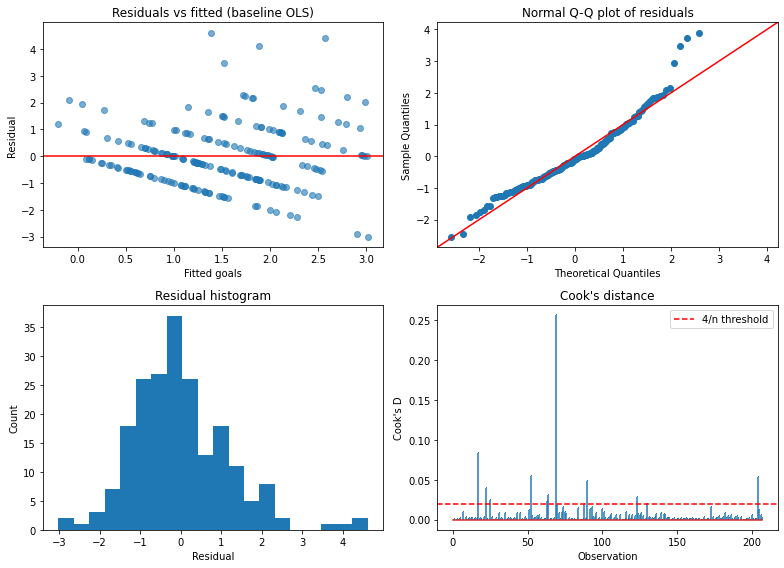

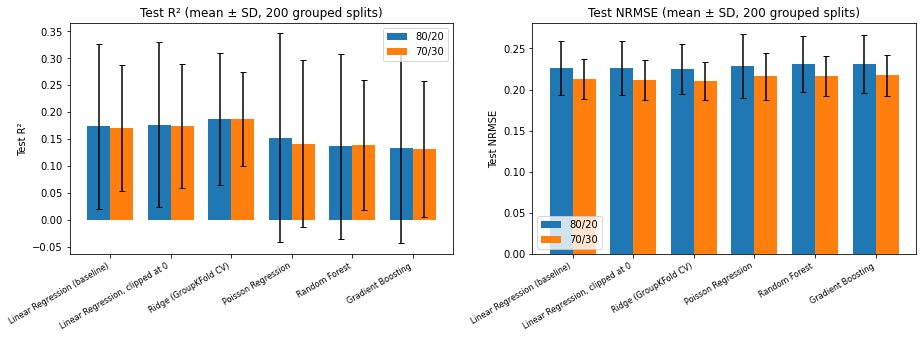

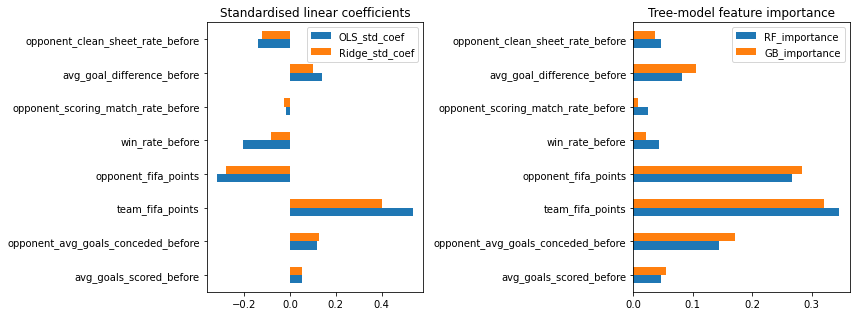

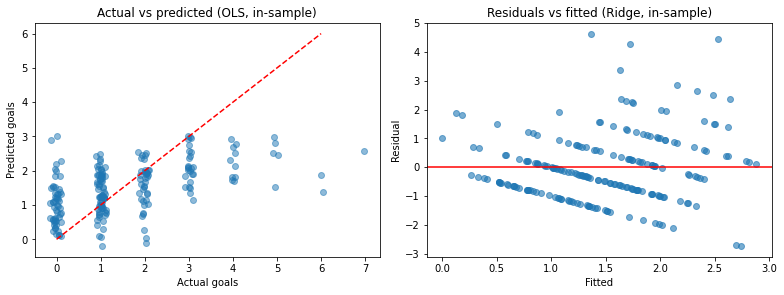

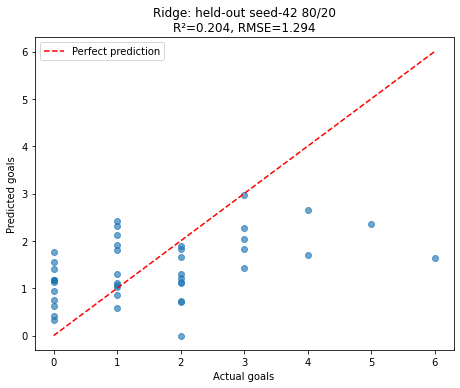


Tuned Gradient Boosting (seed-42 80/20 holdout): {'learning_rate': 0.03, 'max_depth': 1, 'n_estimators': 150} {'R2': 0.16157315022925256, 'RMSE': 1.328451712731982, 'NRMSE': 0.22140861878866366, 'MAE': 1.039814477222699}
Best mean test R² across 200 repeated 80/20 splits: Ridge (GroupKFold CV) (R²=0.1873, RMSE=1.2353).
Best mean test R² across 200 repeated 70/30 splits: Ridge (GroupKFold CV) (R²=0.1878, RMSE=1.2336).
Interpret cautiously: repeated random splits overlap; compare model complexity and stability.
The separately tuned GB seed-42 experiment is NOT included in the repeated-model ranking.
Full-data diagnostics and feature importances are in-sample descriptive analyses.
Upstream pre-match feature construction still requires independent verification.

Saved all outputs to /Users/anishbhattarai/Desktop/College_Assignments/Fifa/Group_Assingement_03/Regression_2.2/results_2_2


In [1]:
"""Regression 2.2 (v2) - goals_scored, 208 team-match rows, 104 matches.
Jupyter-friendly version: robust CSV path, inline plots, quick-test switch, progress output.
The 8 locked predictors are NOT changed."""
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression, PoissonRegressor, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold, GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.diagnostic import het_breuschpagan, het_white
from statsmodels.stats.outliers_influence import variance_inflation_factor

# ------------------------------ CONFIG ------------------------------
# >>> EDIT THIS if the CSV is not in the notebook's working directory <<<
CSV_PATH = "regression_2_2_dataset.csv"        # e.g. r"C:\Users\you\Downloads\regression_2_2_dataset.csv"
OUT = "results_2_2/"
QUICK = False          # True = only 5 repeats, to test that everything runs in seconds
N_JOBS = 1             # 1 is safest in Jupyter; try -1 later for speed

if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(
        f"Cannot find '{CSV_PATH}'. Current folder is: {os.getcwd()}\n"
        f"Files here: {os.listdir()}\nSet CSV_PATH to the full path of your file.")
os.makedirs(OUT, exist_ok=True)

TARGET, GROUP, SEED = "goals_scored", "match_id", 42
N_REPEATS = 5 if QUICK else 200
FEATURES = ["avg_goals_scored_before", "opponent_avg_goals_conceded_before", "team_fifa_points",
            "opponent_fifa_points", "win_rate_before", "opponent_scoring_match_rate_before",
            "avg_goal_difference_before", "opponent_clean_sheet_rate_before"]
ALPHAS = np.logspace(-2, 3, 20)
# --------------------------------------------------------------------
df = pd.read_csv(CSV_PATH)
print("Loaded:", df.shape)
missing = [c for c in FEATURES + [TARGET, GROUP] if c not in df.columns]
assert not missing, f"Missing columns in CSV: {missing}"
assert df[FEATURES + [TARGET]].isna().sum().sum() == 0, "NaNs found in features/target"
if not (len(df) == 208 and df[GROUP].nunique() == 104):
    print(f"WARNING: expected 208 rows / 104 matches, got {len(df)} / {df[GROUP].nunique()}")
X, y, g = df[FEATURES], df[TARGET], df[GROUP]
# Validate the two team-match records per match and finite pre-match features.
assert len(df) == 208 and df[GROUP].nunique() == 104, "Expected 208 rows and 104 matches"
assert df.groupby(GROUP).size().eq(2).all(), "Every match must have two team observations"
assert np.isfinite(df[FEATURES + [TARGET]].to_numpy(dtype=float)).all(), "Non-finite feature/target"
assert (y >= 0).all() and np.allclose(y, np.round(y)), "Goals must be nonnegative integer counts"
assert (df.groupby(GROUP)['team_id'].nunique() == 2).all(), "Expected two distinct teams per match"
# NRMSE denominator is the observed range in the evaluated partition (Bibek's convention).


def metrics(t, p):
    rmse = np.sqrt(mean_squared_error(t, p))
    return dict(R2=r2_score(t, p), RMSE=rmse, NRMSE=rmse / np.ptp(np.asarray(t)) if np.ptp(np.asarray(t)) > 0 else np.nan, MAE=mean_absolute_error(t, p))


# ---------- 1. Group-aware Ridge: GridSearchCV + GroupKFold ----------
def make_ridge():
    return GridSearchCV(make_pipeline(StandardScaler(), Ridge()),
                        {"ridge__alpha": ALPHAS}, cv=GroupKFold(5), scoring="neg_mean_squared_error")


class Model:
    def __init__(s, name, est, clip=False, grouped_cv=False):
        s.name, s.est, s.clip, s.grouped_cv = name, est, clip, grouped_cv

    def fit_predict(s, Xtr, ytr, gtr, Xte):
        m = clone(s.est)
        if s.grouped_cv:
            m.fit(Xtr, ytr, groups=gtr)
        else:
            m.fit(Xtr, ytr)
        out = [m.predict(Xtr), m.predict(Xte)]
        if s.clip:
            out = [np.clip(o, 0, None) for o in out]
        alpha = m.best_params_["ridge__alpha"] if s.grouped_cv else np.nan
        return out[0], out[1], alpha


models = [
    Model("Linear Regression (baseline)", LinearRegression()),
    Model("Linear Regression, clipped at 0", LinearRegression(), clip=True),
    Model("Ridge (GroupKFold CV)", make_ridge(), clip=True, grouped_cv=True),
    Model("Poisson Regression", make_pipeline(StandardScaler(), PoissonRegressor(alpha=1e-3, max_iter=1000))),
    Model("Random Forest", RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                                                 random_state=SEED, n_jobs=N_JOBS)),
    Model("Gradient Boosting", GradientBoostingRegressor(n_estimators=100, max_depth=2, learning_rate=0.05,
                                                        subsample=0.8, random_state=SEED)),
]

rows = []
for seed in range(N_REPEATS):
    if seed % 10 == 0:
        print(f"  repeat {seed}/{N_REPEATS} ...", flush=True)
    for ts in (0.2, 0.3):
        tr, te = next(GroupShuffleSplit(1, test_size=ts, random_state=seed).split(df, y, g))
        for m in models:
            ptr, pte, a = m.fit_predict(X.iloc[tr], y.iloc[tr], g.iloc[tr], X.iloc[te])
            r = dict(model=m.name, split=f"{round((1-ts)*100)}/{round(ts*100)}", seed=seed, alpha=a)
            r.update({f"{k}_train": v for k, v in metrics(y.iloc[tr], ptr).items()})
            r.update({f"{k}_test": v for k, v in metrics(y.iloc[te], pte).items()})
            rows.append(r)
rep = pd.DataFrame(rows)
rep.to_csv(OUT + "all_splits_long.csv", index=False)

cols = ["R2_train", "R2_test", "RMSE_test", "MAE_test", "NRMSE_train", "NRMSE_test"]
summ = rep.groupby(["model", "split"], sort=False)[cols].agg(["mean", "std"]).round(4)
summ.to_csv(OUT + "summary_repeated_splits.csv")
print(f"\n=== {N_REPEATS} repeated grouped splits (mean, std) ===\n", summ.to_string())

single = rep[rep.seed == SEED][["model", "split"] + [c for c in rep.columns if c.endswith(("_train", "_test"))]].round(4) \
    if SEED < N_REPEATS else pd.DataFrame()
if len(single):
    single.to_csv(OUT + "single_split_seed42.csv", index=False)
    print("\n=== Seed 42 (all metrics) ===\n", single.to_string(index=False))

# ---------- 2. Ridge alpha clarification ----------
al = rep[rep.model == "Ridge (GroupKFold CV)"].groupby("split")["alpha"].describe()[["mean", "50%", "min", "max"]]
print("\n=== Alpha selected by GroupKFold CV inside each training split ===\n", al.round(2).to_string())
final_ridge = make_ridge().fit(X, y, groups=g)
print("Alpha chosen on the FULL data (GroupKFold):", round(final_ridge.best_params_["ridge__alpha"], 3),
      "(only used for the final fitted model / coefficients, not for evaluation)")

# ---------- 3. Paired comparison vs baseline ----------
base = rep[rep.model == "Linear Regression (baseline)"].set_index(["split", "seed"])
paired = []
for m in models[1:]:
    d = rep[rep.model == m.name].set_index(["split", "seed"])
    for sp in ["80/20", "70/30"]:
        dr = d.loc[sp, "R2_test"] - base.loc[sp, "R2_test"]
        dn = d.loc[sp, "NRMSE_test"] - base.loc[sp, "NRMSE_test"]
        paired.append(dict(model=m.name, split=sp, mean_dR2=dr.mean(), pct_better_R2=100 * (dr > 0).mean(),
                           mean_dNRMSE=dn.mean(), pct_better_NRMSE=100 * (dn < 0).mean()))
paired = pd.DataFrame(paired).round(4)
paired.to_csv(OUT + "paired_vs_baseline.csv", index=False)
print("\n=== Paired vs baseline (same splits) ===\n", paired.to_string(index=False))

# ---------- 4. Diagnostics on baseline OLS ----------
Xc = sm.add_constant(X); ols = sm.OLS(y, Xc).fit(); res, fit = ols.resid, ols.fittedvalues
sw = stats.shapiro(res); jb = stats.jarque_bera(res); bp = het_breuschpagan(res, Xc); wh = het_white(res, Xc)
diag = pd.DataFrame([
    ["Shapiro-Wilk (normality)", sw[0], sw[1]],
    ["Jarque-Bera (normality)", jb[0], jb[1]],
    ["Breusch-Pagan (heteroscedasticity)", bp[0], bp[1]],
    ["White (heteroscedasticity)", wh[0], wh[1]],
], columns=["test", "statistic", "p_value"])
print("\n=== Diagnostics (baseline OLS, full data) ===\n", diag.round(5).to_string(index=False))
print("Residual skew:", round(stats.skew(res), 3), "| excess kurtosis:", round(stats.kurtosis(res), 3),
      "| Durbin-Watson:", round(sm.stats.durbin_watson(res), 3), "| negative predictions:", int((fit < 0).sum()))
pr = np.array([grp.values for _, grp in res.groupby(g) if len(grp) == 2])
print("Within-match residual correlation:", round(np.corrcoef(pr[:, 0], pr[:, 1])[0, 1], 3))
cooks = ols.get_influence().cooks_distance[0]
print("Cook's D > 4/n:", int((cooks > 4 / len(df)).sum()), "rows | max Cook's D:", round(cooks.max(), 3))
vif = pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])], FEATURES)
print("Max VIF:", round(vif.max(), 3), "| R2:", round(ols.rsquared, 4), "| adj R2:", round(ols.rsquared_adj, 4))
diag.to_csv(OUT + "diagnostic_tests.csv", index=False)

# ---------- 5. Feature importance ----------
Z = StandardScaler().fit_transform(X)
std_coef = pd.Series(np.asarray(sm.OLS(y, sm.add_constant(Z)).fit().params)[1:], index=FEATURES)
ridge_coef = pd.Series(final_ridge.best_estimator_.named_steps["ridge"].coef_, index=FEATURES)
rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=N_JOBS).fit(X, y)
gb = GradientBoostingRegressor(n_estimators=100, max_depth=2, learning_rate=0.05, subsample=0.8,
                               random_state=SEED).fit(X, y)
imp = pd.DataFrame({"OLS_std_coef": std_coef, "Ridge_std_coef": ridge_coef,
                    "RF_importance": rf.feature_importances_, "GB_importance": gb.feature_importances_}).round(4)
imp.to_csv(OUT + "feature_importance.csv"); print("\n=== Feature importance ===\n", imp.to_string())

# ---------- 6. Plots (saved AND shown inline) ----------
fig, ax = plt.subplots(2, 2, figsize=(11, 8))
ax[0, 0].scatter(fit, res, alpha=.6); ax[0, 0].axhline(0, c="r")
ax[0, 0].set(title="Residuals vs fitted (baseline OLS)", xlabel="Fitted goals", ylabel="Residual")
sm.qqplot(res, line="45", fit=True, ax=ax[0, 1]); ax[0, 1].set_title("Normal Q-Q plot of residuals")
ax[1, 0].hist(res, bins=20); ax[1, 0].set(title="Residual histogram", xlabel="Residual", ylabel="Count")
ax[1, 1].stem(np.asarray(cooks), markerfmt=","); ax[1, 1].axhline(4 / len(df), c="r", ls="--", label="4/n threshold")
ax[1, 1].set(title="Cook's distance", xlabel="Observation", ylabel="Cook's D"); ax[1, 1].legend()
plt.tight_layout(); plt.savefig(OUT + "diagnostics_2_2.png", dpi=150); plt.show()

order = [m.name for m in models]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for k, (metric, lab) in enumerate([("R2_test", "Test R²"), ("NRMSE_test", "Test NRMSE")]):
    for j, sp in enumerate(["80/20", "70/30"]):
        s = rep[rep.split == sp].groupby("model")[metric].agg(["mean", "std"]).loc[order]
        ax[k].bar(np.arange(len(order)) + j * 0.38, s["mean"], 0.38, yerr=s["std"], capsize=3, label=sp)
    ax[k].set_xticks(np.arange(len(order)) + 0.19); ax[k].set_xticklabels(order, rotation=30, ha="right", fontsize=8)
    ax[k].set(title=f"{lab} (mean ± SD, {N_REPEATS} grouped splits)", ylabel=lab); ax[k].legend()
plt.tight_layout(); plt.savefig(OUT + "model_comparison.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
imp[["OLS_std_coef", "Ridge_std_coef"]].plot.barh(ax=ax[0]); ax[0].set_title("Standardised linear coefficients")
imp[["RF_importance", "GB_importance"]].plot.barh(ax=ax[1]); ax[1].set_title("Tree-model feature importance")
plt.tight_layout(); plt.savefig(OUT + "feature_importance.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
rp = np.clip(final_ridge.predict(X), 0, None)
ax[0].scatter(y + np.random.default_rng(0).normal(0, .06, len(y)), fit, alpha=.5); ax[0].plot([0, 6], [0, 6], "r--")
ax[0].set(title="Actual vs predicted (OLS, in-sample)", xlabel="Actual goals", ylabel="Predicted goals")
ax[1].scatter(rp, y - rp, alpha=.6); ax[1].axhline(0, c="r")
ax[1].set(title="Residuals vs fitted (Ridge, in-sample)", xlabel="Fitted", ylabel="Residual")
plt.tight_layout(); plt.savefig(OUT + "actual_vs_predicted_and_ridge_residuals.png", dpi=150); plt.show()
# ---------- 7. True held-out prediction chart (seed 42, 80/20) ----------
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(X, y, g))
selected = make_ridge().fit(X.iloc[tr], y.iloc[tr], groups=g.iloc[tr])
held_pred = np.clip(selected.predict(X.iloc[te]), 0, None)
held_actual = y.iloc[te].to_numpy()
held_metrics = metrics(held_actual, held_pred)
held_df = pd.DataFrame({"match_id": g.iloc[te].to_numpy(), "actual_goals": held_actual,
                        "predicted_goals": held_pred, "residual": held_actual - held_pred})
held_df.to_csv(OUT + "ridge_seed42_heldout_predictions.csv", index=False)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(held_actual, held_pred, alpha=0.65)
lo = min(held_actual.min(), held_pred.min()); hi = max(held_actual.max(), held_pred.max())
ax.plot([lo, hi], [lo, hi], 'r--', label='Perfect prediction')
ax.set(xlabel='Actual goals', ylabel='Predicted goals',
       title=f"Ridge: held-out seed-42 80/20\nR²={held_metrics['R2']:.3f}, RMSE={held_metrics['RMSE']:.3f}")
ax.legend(); plt.tight_layout()
plt.savefig(OUT + 'ridge_heldout_actual_vs_predicted.png', dpi=150); plt.show()

# ---------- 8. Training-only group-aware optimisation of one nonlinear competitor ----------
# Single seed-42 experiment: do not confuse with the 200 repeated fixed-parameter comparisons.
gb_grid = {"n_estimators": [80, 150], "max_depth": [1, 2], "learning_rate": [0.03, 0.08]}
gb_search = GridSearchCV(
    GradientBoostingRegressor(min_samples_leaf=3, subsample=0.8, random_state=SEED),
    gb_grid, cv=GroupKFold(5), scoring='neg_mean_squared_error', n_jobs=N_JOBS)
gb_search.fit(X.iloc[tr], y.iloc[tr], groups=g.iloc[tr])
gb_pred = gb_search.predict(X.iloc[te])
gb_score = metrics(y.iloc[te], gb_pred)
print('\nTuned Gradient Boosting (seed-42 80/20 holdout):', gb_search.best_params_, gb_score)
pd.DataFrame([{'model':'Tuned Gradient Boosting', 'split':'80/20', 'seed':SEED,
               **gb_search.best_params_, **{k+'_test':v for k,v in gb_score.items()}}]).to_csv(
               OUT + 'tuned_gb_seed42.csv', index=False)

# ---------- 9. Evidence-based summary from repeated holdouts ----------
summary = rep.groupby(['model', 'split'])[['R2_test', 'RMSE_test', 'MAE_test', 'NRMSE_test']].mean().reset_index()
for split in ('80/20','70/30'):
    best = summary[summary.split == split].sort_values(['R2_test', 'RMSE_test'], ascending=[False, True]).iloc[0]
    print(f"Best mean test R² across {N_REPEATS} repeated {split} splits: {best['model']} "
          f"(R²={best['R2_test']:.4f}, RMSE={best['RMSE_test']:.4f}).")
print('Interpret cautiously: repeated random splits overlap; compare model complexity and stability.')
print('The separately tuned GB seed-42 experiment is NOT included in the repeated-model ranking.')
print('Full-data diagnostics and feature importances are in-sample descriptive analyses.')
print('Upstream pre-match feature construction still requires independent verification.')
print("\nSaved all outputs to", os.path.abspath(OUT))